In [1]:
# ==============================================================================
# PROJETO NEUROSTARTUP: VesteAI - Classificação Automática de Roupas
# ==============================================================================

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # Esconde avisos técnicos desnecessários

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from ipywidgets import interact

# Semente fixa para o resultado ser sempre reproduzível
SEED = 42
keras.utils.set_random_seed(SEED)

print("Ferramentas carregadas! Versão do Keras:", keras.__version__)

# 1. Carregando os dados reais (já vêm separados em treino original e teste/cofre)
(X_treino_bruto, y_treino_bruto), (X_teste_cofre, y_teste_cofre) = keras.datasets.fashion_mnist.load_data()

# Nomes das 10 categorias em português para facilitar a leitura
nomes_categorias = [
    "0 - Camiseta/Top",
    "1 - Calça",
    "2 - Suéter",
    "3 - Vestido",
    "4 - Casaco",
    "5 - Sandália",
    "6 - Camisa",
    "7 - Tênis",
    "8 - Bolsa",
    "9 - Bota"
]

print(f"Total de imagens para desenvolvimento: {len(X_treino_bruto)}")
print(f"Total de imagens trancadas no COFRE (teste final): {len(X_teste_cofre)}")

Ferramentas carregadas! Versão do Keras: 3.13.2
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total de imagens para desenvolvimento: 60000
Total de imagens trancadas no COFRE (teste final): 10000


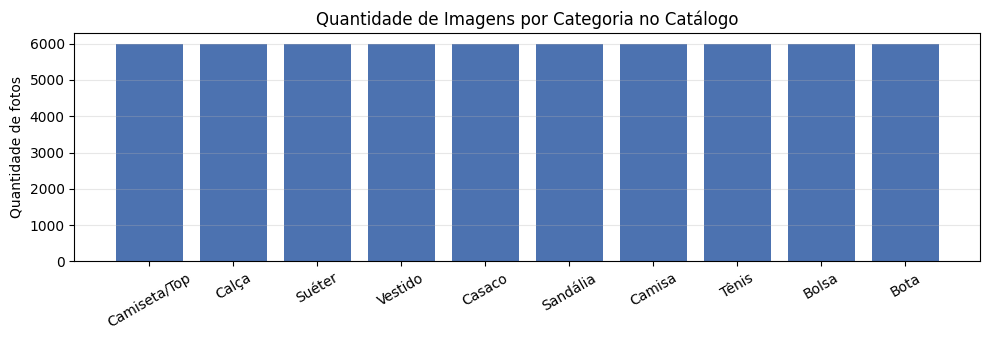

📌 Conclusão Gráfico 1: Todas as 10 categorias têm exatamente 6.000 fotos cada. A base é totalmente equilibrada, evitando que a rede fique viciada em um tipo específico de roupa.



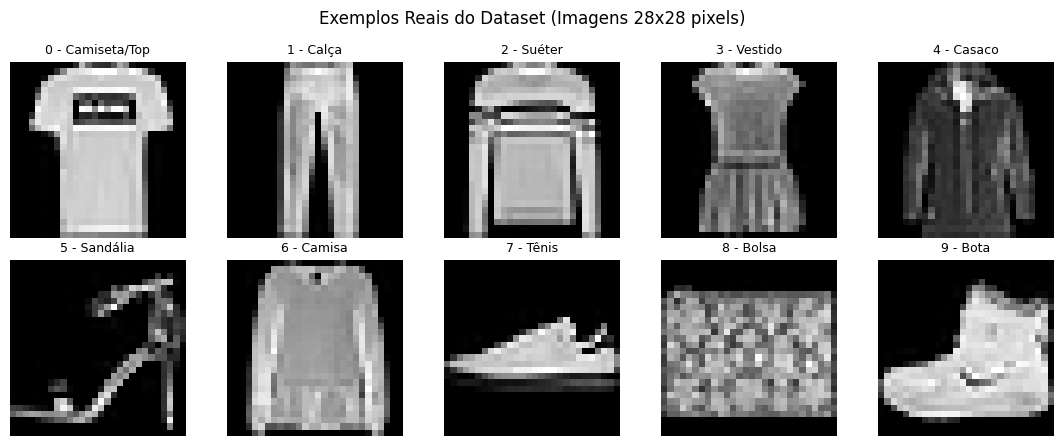

📌 Conclusão Gráfico 2: As fotos têm 28x28 pixels em tons de cinza (0 a 255). Peças como Camiseta, Suéter e Camisa têm formatos muito parecidos, o que exige uma rede neural para captar detalhes internos.

Divisão final -> Treino: 48000 | Validação: 12000 | Cofre (Teste): 10000


In [2]:
# ===== 1 · Conhecer os dados (2 gráficos + conclusão) =====

# Gráfico 1: Quantidade de imagens por categoria
contagem = pd.Series(y_treino_bruto).value_counts().sort_index()
plt.figure(figsize=(10, 3.5))
plt.bar([nomes_categorias[i].split(" - ")[1] for i in contagem.index], contagem.values, color="#4C72B0")
plt.title("Quantidade de Imagens por Categoria no Catálogo")
plt.ylabel("Quantidade de fotos")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print("📌 Conclusão Gráfico 1: Todas as 10 categorias têm exatamente 6.000 fotos cada. A base é totalmente equilibrada, evitando que a rede fique viciada em um tipo específico de roupa.\n")

# Gráfico 2: Mostrando 1 exemplo real de cada categoria
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for categoria in range(10):
    ax = axes[categoria // 5, categoria % 5]
    primeiro_indice = np.where(y_treino_bruto == categoria)[0][0]
    ax.imshow(X_treino_bruto[primeiro_indice], cmap="gray")
    ax.set_title(nomes_categorias[categoria], fontsize=9)
    ax.axis("off")
plt.suptitle("Exemplos Reais do Dataset (Imagens 28x28 pixels)", fontsize=12)
plt.tight_layout()
plt.show()
print("📌 Conclusão Gráfico 2: As fotos têm 28x28 pixels em tons de cinza (0 a 255). Peças como Camiseta, Suéter e Camisa têm formatos muito parecidos, o que exige uma rede neural para captar detalhes internos.\n")

# Normalização: dividindo os pixels por 255 para ficarem entre 0 e 1 (ajuda a rede a aprender melhor)
X_normalizado = X_treino_bruto / 255.0
X_teste_norm = X_teste_cofre / 255.0

# 🔒 Regra do Cofre:
# X_teste_norm fica trancado até o Passo 3.
# Dividimos os 60.000 dados restantes em 48.000 para Treino e 12.000 para Validação ("simulado")
X_treino, X_valid, y_treino, y_valid = train_test_split(
    X_normalizado, y_treino_bruto, test_size=0.2, random_state=SEED, stratify=y_treino_bruto
)

# Versão "achatada" (28x28 = 784 colunas) para rodar os modelos clássicos do scikit-learn
X_treino_tabela = X_treino.reshape(len(X_treino), 784)
X_valid_tabela = X_valid.reshape(len(X_valid), 784)
X_teste_tabela = X_teste_norm.reshape(len(X_teste_norm), 784)

print(f"Divisão final -> Treino: {len(X_treino)} | Validação: {len(X_valid)} | Cofre (Teste): {len(X_teste_norm)}")

📏 Baseline (Árvore de Decisão) -> Acurácia na validação: 81.9%


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


⭐ Modelo Extra Bônus (Regressão Logística) -> Acurácia na validação: 86.1%

Testado -> Rede 1: Simples (32 neurônios) | Épocas: 24 | Acurácia Validação: 88.0%
Testado -> Rede 2: Média (128 neurônios) | Épocas: 25 | Acurácia Validação: 89.7%
Testado -> Rede 3: Profunda (128 + 64 neurônios) | Épocas: 15 | Acurácia Validação: 88.8%

Tabela salva em 'experimentos.csv':
                          arquitetura  epocas_treinadas  acuracia_validacao
       Rede 1: Simples (32 neurônios)                24               88.02
        Rede 2: Média (128 neurônios)                25               89.75
Rede 3: Profunda (128 + 64 neurônios)                15               88.81


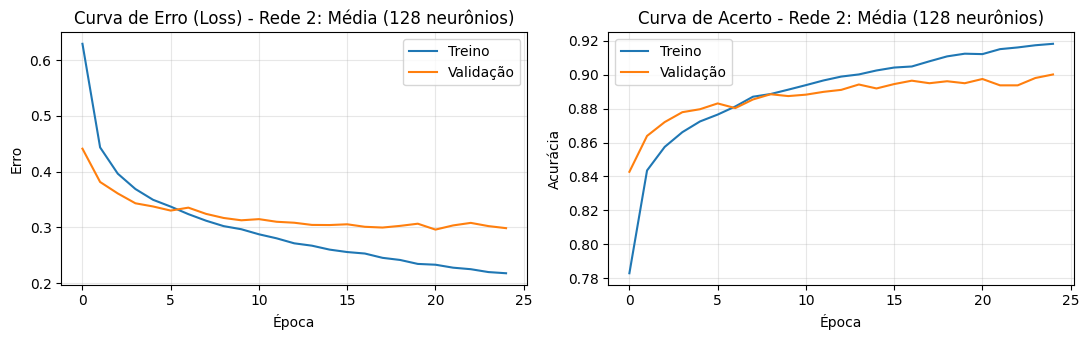

In [3]:
# ===== 2 · Baseline × Rede Neural (e registro no experimentos.csv) =====

# 1. Modelo Simples (Baseline): Árvore de Decisão
baseline = DecisionTreeClassifier(max_depth=12, random_state=SEED)
baseline.fit(X_treino_tabela, y_treino)
acc_baseline_val = accuracy_score(y_valid, baseline.predict(X_valid_tabela))
print(f"📏 Baseline (Árvore de Decisão) -> Acurácia na validação: {acc_baseline_val:.1%}")

# ⭐ Bônus: Comparação com um segundo modelo clássico (Regressão Logística)
modelo_bonus = LogisticRegression(max_iter=100, random_state=SEED)
modelo_bonus.fit(X_treino_tabela, y_treino)
acc_bonus_val = accuracy_score(y_valid, modelo_bonus.predict(X_valid_tabela))
print(f"⭐ Modelo Extra Bônus (Regressão Logística) -> Acurácia na validação: {acc_bonus_val:.1%}\n")

# 2. Testando 3 arquiteturas diferentes de Rede Neural no Keras
arquiteturas = [
    {"nome": "Rede 1: Simples (32 neurônios)", "camadas": [32]},
    {"nome": "Rede 2: Média (128 neurônios)", "camadas": [128]},
    {"nome": "Rede 3: Profunda (128 + 64 neurônios)", "camadas": [128, 64]},
]

registros = []
melhor_acc = 0
melhor_modelo = None
melhor_historico = None
melhor_nome = ""

for config in arquiteturas:
    keras.utils.set_random_seed(SEED)

    # Montando a rede como Lego
    modelo = keras.Sequential()
    modelo.add(keras.Input(shape=(28, 28)))
    modelo.add(layers.Flatten())  # Transforma a imagem 28x28 em uma linha de 784 números

    for qtd_neuronios in config["camadas"]:
        modelo.add(layers.Dense(qtd_neuronios, activation="relu"))
        modelo.add(layers.Dropout(0.2))  # Evita que a rede decore (overfitting)

    modelo.add(layers.Dense(10, activation="softmax"))  # 10 categorias possíveis

    modelo.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Early Stopping: para o treino se o simulado (validação) parar de melhorar por 4 épocas
    parada_antecipada = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    historico = modelo.fit(
        X_treino, y_treino,
        validation_data=(X_valid, y_valid),
        epochs=25,
        batch_size=128,
        callbacks=[parada_antecipada],
        verbose=0
    )

    _, acc_val = modelo.evaluate(X_valid, y_valid, verbose=0)
    epocas_rodadas = len(historico.history["loss"])

    registros.append({
        "arquitetura": config["nome"],
        "epocas_treinadas": epocas_rodadas,
        "acuracia_validacao": round(acc_val * 100, 2)
    })

    print(f"Testado -> {config['nome']} | Épocas: {epocas_rodadas} | Acurácia Validação: {acc_val:.1%}")

    if acc_val > melhor_acc:
        melhor_acc = acc_val
        melhor_modelo = modelo
        melhor_historico = historico
        melhor_nome = config["nome"]

# Salvando a tabela de tentativas no experimentos.csv
df_experimentos = pd.DataFrame(registros)
df_experimentos.to_csv("experimentos.csv", index=False)
print("\nTabela salva em 'experimentos.csv':")
print(df_experimentos.to_string(index=False))

# Gráfico das curvas de aprendizado da melhor rede
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

ax1.plot(melhor_historico.history["loss"], label="Treino")
ax1.plot(melhor_historico.history["val_loss"], label="Validação")
ax1.set_title(f"Curva de Erro (Loss) - {melhor_nome}")
ax1.set_xlabel("Época")
ax1.set_ylabel("Erro")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(melhor_historico.history["accuracy"], label="Treino")
ax2.plot(melhor_historico.history["val_accuracy"], label="Validação")
ax2.set_title(f"Curva de Acerto - {melhor_nome}")
ax2.set_xlabel("Época")
ax2.set_ylabel("Acurácia")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
# ===== 3 · Abrir o cofre (avaliar no teste UMA ÚNICA VEZ) =====

acc_baseline_teste = accuracy_score(y_teste_cofre, baseline.predict(X_teste_tabela))
_, acc_rede_teste = melhor_modelo.evaluate(X_teste_norm, y_teste_cofre, verbose=0)

erro_baseline = 1 - acc_baseline_teste
erro_rede = 1 - acc_rede_teste
reducao_erro = 1 - (erro_rede / erro_baseline)

print(f"🔓 RESULTADO FINAL NO COFRE (10.000 imagens inéditas):")
print(f"• Modelo Simples (Árvore de Decisão): {acc_baseline_teste:.1%} de acerto")
print(f"• Melhor Rede Neural ({melhor_nome}): {acc_rede_teste:.1%} de acerto")
print("-" * 65)
print(
    f"💼 FRASE DE NEGÓCIO: A cada 1.000 peças cadastradas pelos lojistas, nossa rede neural "
    f"classifica corretamente cerca de {round(acc_rede_teste * 1000)} roupas de forma automática "
    f"(contra {round(acc_baseline_teste * 1000)} do modelo simples), reduzindo em {reducao_erro:.0%} "
    f"os erros manuais de catalogação."
)

🔓 RESULTADO FINAL NO COFRE (10.000 imagens inéditas):
• Modelo Simples (Árvore de Decisão): 80.8% de acerto
• Melhor Rede Neural (Rede 2: Média (128 neurônios)): 88.7% de acerto
-----------------------------------------------------------------
💼 FRASE DE NEGÓCIO: A cada 1.000 peças cadastradas pelos lojistas, nossa rede neural classifica corretamente cerca de 887 roupas de forma automática (contra 808 do modelo simples), reduzindo em 41% os erros manuais de catalogação.


In [5]:
# ===== 4 · Produto: Salvar o modelo + Função de previsão + Tela interativa =====

# Salvando o modelo treinado em arquivo
melhor_modelo.save("modelo_vesteai.keras")
modelo_producao = keras.models.load_model("modelo_vesteai.keras")
print("📦 Modelo salvo com sucesso como 'modelo_vesteai.keras'!")

# Função que recebe uma foto do catálogo e devolve a previsão
def classificar_peca(indice_foto=0):
    imagem = X_teste_norm[indice_foto]
    categoria_real = nomes_categorias[y_teste_cofre[indice_foto]]

    # A rede espera um lote de imagens, então adicionamos uma dimensão extra (1, 28, 28)
    lote = np.expand_dims(imagem, axis=0)
    probabilidades = modelo_producao.predict(lote, verbose=0)[0]

    indice_previsto = int(np.argmax(probabilidades))
    categoria_prevista = nomes_categorias[indice_previsto]
    confianca = probabilidades[indice_previsto] * 100

    acertou = "✅ ACERTOU" if indice_previsto == y_teste_cofre[indice_foto] else "❌ ERROU"

    plt.figure(figsize=(3, 3))
    plt.imshow(imagem, cmap="gray")
    plt.title(f"Peça #{indice_foto} ({acertou})", fontsize=10)
    plt.axis("off")
    plt.show()

    print(f"👕 Categoria sugerida pela IA: {categoria_prevista}")
    print(f"📊 Confiança do modelo: {confianca:.1f}%")
    print(f"🏷️ Categoria real da etiqueta: {categoria_real}")

# Painel interativo para testar qualquer uma das 10.000 peças do teste
print("\n🖥️ Arraste o controle abaixo para testar o sistema na prática:")
interact(classificar_peca, indice_foto=(0, len(X_teste_norm) - 1, 1));

📦 Modelo salvo com sucesso como 'modelo_vesteai.keras'!

🖥️ Arraste o controle abaixo para testar o sistema na prática:


interactive(children=(IntSlider(value=0, description='indice_foto', max=9999), Output()), _dom_classes=('widge…

In [6]:
# ===== 5 · Documentação: Gerando MODEL_CARD.md e README.md =====

model_card_texto = f"""# Model Card — Classificador de Roupas VesteAI

- **Uso pretendido:** Sugerir automaticamente a categoria de peças de vestuário (entre 10 tipos) a partir de fotos enviadas por lojistas durante o cadastro de produtos em marketplaces.
- **Não usar para:** Bloquear contas de vendedores automaticamente, aplicar multas por erro de cadastro ou avaliar qualidade/originalidade de marcas sem revisão humana.
- **Dados:** 70.000 imagens em tons de cinza (28x28 pixels) do dataset público Fashion-MNIST, divididas em 48.000 para treino, 12.000 para validação e 10.000 para teste final.
- **Modelo:** Rede Neural ({melhor_nome}) construída em Keras com camadas Dense, ReLU, Dropout (0.2) e Early Stopping, comparada a um baseline de Árvore de Decisão.
- **Desempenho no teste:** Acurácia de {acc_rede_teste:.1%} (contra {acc_baseline_teste:.1%} do baseline simples), reduzindo em {reducao_erro:.0%} os erros de classificação.
- **Limitações:** Treinado apenas com imagens centralizadas em fundo neutro e escala de cinza (28x28). Fotos reais tiradas por celular com fundo bagunçado, iluminação ruim ou ângulos diferentes exigirão re-treino com fotos reais da plataforma.
"""

with open("MODEL_CARD.md", "w", encoding="utf-8") as f:
    f.write(model_card_texto)

print("📄 Arquivo 'MODEL_CARD.md' criado com sucesso!")
print("-" * 50)
print(model_card_texto)

📄 Arquivo 'MODEL_CARD.md' criado com sucesso!
--------------------------------------------------
# Model Card — Classificador de Roupas VesteAI

- **Uso pretendido:** Sugerir automaticamente a categoria de peças de vestuário (entre 10 tipos) a partir de fotos enviadas por lojistas durante o cadastro de produtos em marketplaces.
- **Não usar para:** Bloquear contas de vendedores automaticamente, aplicar multas por erro de cadastro ou avaliar qualidade/originalidade de marcas sem revisão humana.
- **Dados:** 70.000 imagens em tons de cinza (28x28 pixels) do dataset público Fashion-MNIST, divididas em 48.000 para treino, 12.000 para validação e 10.000 para teste final.
- **Modelo:** Rede Neural (Rede 2: Média (128 neurônios)) construída em Keras com camadas Dense, ReLU, Dropout (0.2) e Early Stopping, comparada a um baseline de Árvore de Decisão.
- **Desempenho no teste:** Acurácia de 88.7% (contra 80.8% do baseline simples), reduzindo em 41% os erros de classificação.
- **Limitações:** T